<a href="https://colab.research.google.com/github/Abdoulaye279/Financial-Engineering/blob/main/var-es-sp500/01_sp500_tails.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 - S&P 500 returns: tails and volatility

What the VaR models will have to deal with. Daily closes 2000-2026 (same file as the Black-Scholes project).

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Financial-Engineering
    %cd Financial-Engineering/var-es-sp500
except ImportError:
    pass

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from risk import *
plt.style.use("quant.mplstyle")

spx = load_close("../black-scholes-sp500/data/sp500.csv").loc["2000":]
rets = np.log(spx).diff().dropna()
len(rets), rets.index[0].date(), rets.index[-1].date()

(6761, datetime.date(2000, 1, 4), datetime.date(2026, 11, 19))

In [3]:
z = (rets - rets.mean()) / rets.std()
print("1% quantile, normal:", round(stats.norm.ppf(0.01), 2), " data:", round(np.quantile(z, 0.01), 2))
print("days below -2.33 sd:", round((z < stats.norm.ppf(0.01)).mean(), 4))
# real 1% quantile is -2.88 sd, not -2.33 -> a normal VaR will be too small
# and the "1% day" of the normal law actually happens on ~2% of days

1% quantile, normal: -2.33  data: -2.88
days below -2.33 sd: 0.0195


In [4]:
omega, a, b = garch_fit(rets.values)
print("alpha", round(a, 3), " beta", round(b, 3), " a+b", round(a + b, 3))
print("long run vol", round(np.sqrt(omega / (1 - a - b) * 252), 3))
print("half-life of a vol shock (days)", round(np.log(0.5) / np.log(a + b)))
# a+b = 0.98: a vol shock takes more than a month to fade by half (vol clustering)

alpha 0.119  beta 0.862  a+b 0.981
long run vol 0.182
half-life of a vol shock (days) 36


In [5]:
x = rets.values - rets.mean()
zr = x / np.sqrt(garch_filter(x, omega, a, b)[:-1])   # garch residuals
print("kurtosis returns", round(stats.kurtosis(x), 2), " residuals", round(stats.kurtosis(zr), 2))
print("jarque-bera p on residuals", stats.jarque_bera(zr).pvalue)
print("residual 1% quantile", round(np.quantile(zr, 0.01), 2))
# garch removes most of the fat tails (10.6 -> 1.8) but the residuals are still not normal
# -> keep garch for the vol, but use an empirical (FHS) or EVT tail instead of the normal one

kurtosis returns 10.64  residuals 1.77
jarque-bera p on residuals 9.728994760702225e-264
residual 1% quantile -2.78


EVT on the residual losses: peaks over threshold (McNeil & Frey 2000). Threshold $u$ = 90% quantile, generalized Pareto on the excesses, then
$VaR = u + \frac{\beta}{\xi}\left[\left(\frac{1-q}{0.10}\right)^{-\xi} - 1\right]$, $ES = \frac{VaR + \beta - \xi u}{1-\xi}$.

u 1.27  xi 0.042  beta 0.649  VaR/ES of residuals [2.84 3.58]


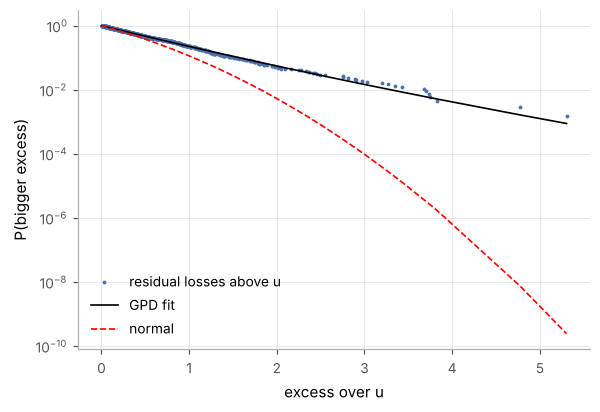

In [6]:
losses = -zr
u = np.quantile(losses, 0.9)
excess = losses[losses > u] - u
xi, _, beta = stats.genpareto.fit(excess, floc=0)
print("u", round(u, 2), " xi", round(xi, 3), " beta", round(beta, 3), " VaR/ES of residuals", np.round(evt_tail(losses), 2))

xs = np.sort(excess)
plt.figure(figsize=(6, 4))
plt.plot(xs, 1 - np.arange(1, len(xs) + 1) / (len(xs) + 1), ".", ms=3, label="residual losses above u")
plt.plot(xs, stats.genpareto.sf(xs, xi, scale=beta), "k", label="GPD fit")
plt.plot(xs, stats.norm.sf(xs + u) / stats.norm.sf(u), "r--", label="normal")
plt.yscale("log"); plt.xlabel("excess over u"); plt.ylabel("P(bigger excess)"); plt.legend()
plt.show()
# gpd follows the tail, the normal drops way too fast